In [13]:
import copy 
import random 
import time 
from pathlib import Path 
import json

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import torch 
from torch import nn 
from sklearn.preprocessing import StandardScaler

In [14]:
FEATURES = ['S0', 'K', 'T', 'r', 'v0', 'kappa', 'theta', 'sigma', 'rho']
TRAIN_N, VALIDATION_N, TEST_N = 12000, 200, 500 
EPOCHS, PATIENCE, BATCH_SIZE, LEARNING_RATE, MIN_DELTA = 1000, 100, 64, 1e-3, 1e-7
MODEL_SEED = (42, 43, 44)

RUN_TRAINING = False

ARCHITECTURES = {
    'Shallow': (128, ), 
    'Deep': (128, 128, 128, 128, 128), 
    'Narrow': (64, 64, 64), 
    'Baseline': (128, 128, 128), 
    'Wide': (256, 256, 256),
}

BASELINE_RESULTS_DIR = Path('experiment_baseline')
DATA_DIR = Path('experiment_training_size_results')/'data'
OUTPUT_DIR = Path('experiment_architecture_results')/f'n{TRAIN_N}'
MODEL_DIR = OUTPUT_DIR / 'models'
HISTORY_DIR = OUTPUT_DIR / 'histories'
PREDICTION_DIR = OUTPUT_DIR / 'predictions'
FIGURE_DIR = OUTPUT_DIR / 'figures'

for directory in (MODEL_DIR, HISTORY_DIR, PREDICTION_DIR, FIGURE_DIR): 
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cpu')
torch.set_num_threads(min(4, torch.get_num_threads()))
print('Torch:', torch.__version__, 
      '| Training size:', TRAIN_N)

Torch: 1.12.1 | Training size: 12000


In [15]:
def check_data(df, name):
    required = FEATURES + ['price']
    missing = [c for c in required if c not in df.columns]
    if missing: 
        raise ValueError(f'{name}: Missing columns: {missing}')
    if not np.isfinite(df[required].to_numpy(dtype=float)).all():
        raise ValueError(f'{name}: Non-finite data detected')
    if (df['price'] < -1e-7).any(): 
        raise ValueError(f'{name}: Materially negative reference prices detected')
    lower = np.maximum(df['S0'] - df['K'] * np.exp(-df['r'] * df['T']),0.0)
    if (df['price'] < lower - 1e-4).any() or (df['price'] > df['S0'] + 1e-4).any():
        raise ValueError(f'{name}: Option prices violate no-arbitrage bounds')
    if df[FEATURES].duplicated().any():
        raise ValueError(f"{name}:Duplicate parameter combinations in a dataset")
base_train = pd.read_csv(BASELINE_RESULTS_DIR/'train.csv')
extension = pd.read_csv(DATA_DIR/'extension_11000.csv')
validation = pd.read_csv(BASELINE_RESULTS_DIR/'validation.csv')
test = pd.read_csv(BASELINE_RESULTS_DIR/'test.csv')

train_pool = pd.concat([base_train, extension], ignore_index=True)
indices = pd.read_csv(DATA_DIR/f'training_indices_{TRAIN_N}.csv')['training_pool_row_index']
if not np.isfinite(indices.to_numpy(dtype=float)).all() or not (indices % 1 == 0).all(): 
    raise ValueError('Training indices must be finite integers')
assert len(base_train) == 1000 and len(extension) == 11000 
assert len(indices) == TRAIN_N and indices.is_unique 
assert (indices >= 0).all() and (indices < len(train_pool)).all()
train = train_pool.iloc[indices.to_numpy(dtype=int)].copy().reset_index(drop=True)

for frame, name in [(train_pool, 'training_pool'), (train, 'train'), (validation, 'validation'), (test, 'test')]: 
    check_data(frame, name) 
assert len(validation) == VALIDATION_N and len(test) == TEST_N 
assert not pd.concat([train_pool, validation, test])[FEATURES].duplicated().any()

x_scaler = StandardScaler().fit(train[FEATURES].to_numpy())
y_scaler = StandardScaler().fit(train[['price']].to_numpy())

def tensor_data(frame): 
    x = torch.tensor(x_scaler.transform(frame[FEATURES].to_numpy()), dtype=torch.float32)
    y = torch.tensor(y_scaler.transform(frame[['price']].to_numpy()), dtype=torch.float32)
    return x,y 

xtr, ytr = tensor_data(train) 
xva, yva = tensor_data(validation)
print(f'Train: {len(train):,}|Validation:{len(validation)}|Test:{len(test)}')

Train: 12,000|Validation:200|Test:500


In [16]:
class MLP(nn.Module): 
    def __init__(self, hidden_units):
        super().__init__()
        layers = []
        width = len(FEATURES)
        for hidden_width in hidden_units: 
            layers.extend([
                nn.Linear(width, hidden_width), 
                nn.ReLU()])
            width = hidden_width
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)
    def forward(self,x):
        return self.net(x)

In [17]:
def metrics(actual, pred): 
    actual = np.asarray(actual, dtype=float).ravel()
    pred = np.asarray(pred, dtype=float).ravel()
    if actual.size == 0 or actual.shape != pred.shape: 
        raise ValueError(
            'Actual and predicted prices must have matching non-empty shapes'
        )
    
    if not np.isfinite(actual).all() or not np.isfinite(pred).all(): 
        raise ValueError('Non-finite prices in evaluation')
    
    error = pred - actual 
    absolute = np.abs(error)
    valid = actual >= 0.01
    return {
        'mae': float(np.mean(absolute)), 
        'rmse': float(np.sqrt(np.mean(error**2))),
        'median_absolute_error': float(np.median(absolute)), 
        'p90_absolute_error': float(np.percentile(absolute, 90)), 
        'max_absolute_error': float(np.max(absolute)), 
        'relative_error_percent_on_prices_above_0_01': (
            float(100 * np.mean(absolute[valid]/actual[valid]))
            if np.any(valid) else None
        ),
    }

In [18]:
def fit_architecture(name, hidden_units, model_seed): 
    random.seed(model_seed)
    np.random.seed(model_seed)
    torch.manual_seed(model_seed)

    net = MLP(hidden_units).to(DEVICE)
    optimizer = torch.optim.Adam(net.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()
    best_loss = float('inf')
    best_state, best_epoch = None, None 
    stale = 0 
    history = []
    start = time.perf_counter()


    for epoch in range(1, EPOCHS+1): 
        net.train()
        perm = torch.randperm(len(xtr))
        for indices in perm.split(BATCH_SIZE): 
            optimizer.zero_grad()
            loss = criterion(net(xtr[indices]), ytr[indices])
            loss.backward()
            optimizer.step()
        net.eval()
        with torch.inference_mode(): 
            train_loss = criterion(net(xtr), ytr).item()
            val_loss = criterion(net(xva), yva).item()
        history.append({
            'architecture':name, 
            'train_n': TRAIN_N, 
            'model_seed': model_seed, 
            'epoch': epoch, 
            'train_mse_scaled': train_loss, 
            'validation_mse_scaled': val_loss
        })
        if not np.isfinite(train_loss) or not np.isfinite(val_loss): 
            raise RuntimeError(f'Non-finite loss: {name}, seed={model_seed}, epoch={epoch}')
        if val_loss < best_loss - MIN_DELTA: 
            best_loss = val_loss
            best_epoch = epoch 
            best_state = copy.deepcopy(net.state_dict())
            stale=0
        else: 
            stale += 1 
        if epoch % 100 == 0:
            print(f'{name} seed={model_seed} epoch={epoch:4d}'
                  f' train MSE={train_loss:.6f}, validation MSE = {val_loss:.6f}')
        if stale >= PATIENCE: 
            break 
    training_seconds = time.perf_counter() - start 
    if best_state is None: 
        raise RuntimeError('No valid checkpoint was obtained')
    net.load_state_dict(best_state)
    net.eval()

    with torch.inference_mode(): 
        prediction = y_scaler.inverse_transform(net(xva).cpu().numpy()).ravel()
    validation_metrics = metrics(validation['price'].to_numpy(), prediction)
    results = {
        'architecture': name, 
        'train_n': TRAIN_N, 
        'layers': len(hidden_units),
        'neurons': hidden_units[0], 
        'model_seed': model_seed, 
        'parameter_count': sum(p.numel() for p in net.parameters()), 
        'training_seconds': float(training_seconds), 
        'best_epoch': best_epoch, 
        'epochs_ran': len(history), 
        'best_validation_mse_scaled': float(best_loss), 
        **{f'validation_{k}': v for k, v in validation_metrics.items()}
    }
    checkpoint = {
        'model_state_dict': net.state_dict(), 
        'features': FEATURES, 
        'hidden_units': hidden_units, 
        'x_mean': x_scaler.mean_, 'x_scale': x_scaler.scale_, 
        'y_mean': y_scaler.mean_, 'y_scale': y_scaler.scale_,
        'model_seed': model_seed, 'train_n': TRAIN_N
    }
    return results, pd.DataFrame(history), checkpoint
     

In [19]:
import inspect 

def load_checkpoint(path): 
    kwargs = {'map_location': DEVICE}
    if 'weigths_only' in inspect.signature(torch.load).parameters: 
        kwargs['weights_only'] = False 
    return torch.load(path, **kwargs)

def restore_model(checkpoint, name, model_seed): 
    if (list(checkpoint['features']) != FEATURES
            or tuple(checkpoint['hidden_units']) != ARCHITECTURES[name]
            or checkpoint['model_seed'] != model_seed
            or checkpoint['train_n'] != TRAIN_N):
        raise ValueError(f'Checkpoint config.  mismatch: {name}, seed={model_seed}')
    for key, expected in [('x_mean', x_scaler.mean_), ('x_scale', x_scaler.scale_), 
                          ('y_mean', y_scaler.mean_), ('y_scale', y_scaler.scale_)]: 
        if not np.allclose(np.asarray(checkpoint[key]), expected, rtol=1e-9, atol=1e-12):
            raise ValueError(f'Checkpoint scaler mismatch: {name}, seed={model_seed}, {key}')
    net = MLP(checkpoint['hidden_units']).to(DEVICE)
    net.load_state_dict(checkpoint['model_state_dict'])
    net.eval()
    return net 

if RUN_TRAINING: 
    trail_results = [] 
    trained = {}

    for name, hidden_units in ARCHITECTURES.items(): 
        for model_seed in MODEL_SEED: 
            stem = f'{name}_seed{model_seed}'
            print(f'\nTraining {name}: {hidden_units}(seed{model_seed})')
            result, history, checkpoint = fit_architecture(name, hidden_units, model_seed)
            history.to_csv(HISTORY_DIR / f'history_{stem}.csv', index=False) 
            torch.save(checkpoint, MODEL_DIR/f'model_{stem}.pt') 
            trained[(name, model_seed)] = checkpoint 
            trail_results.append(result)
            pd.DataFrame(trail_results).to_csv(OUTPUT_DIR / 'architecture_trials.csv', index=False)
            print(f'Validation MAE={result["validation_mae"]:.6f} | '
                  f'RMSE={result["validation_rmse"]:.6f} | '
                  f'Training={result["training_seconds"]:.2f}s')
    trials = pd.DataFrame(trail_results)
else: 
    trials_path = OUTPUT_DIR / 'architecture_trials.csv'
    if not trials_path.exists():
        raise FileNotFoundError(f'{trials_path} is missing. Set RUN_TRAINING = True')
    trials = pd.read_csv(trials_path)
    expected_runs = {(name, seed) for name in ARCHITECTURES for seed in MODEL_SEED}
    actual_runs = set(zip(trials['architecture'], trials['model_seed']))
    if actual_runs != expected_runs or len(trials) != len(expected_runs): 
        raise ValueError('Saved trials do not contain exactly one run per architecture and seed')
    trained = {}
    for name, model_seed in sorted(expected_runs): 
        row = trials.loc[(trials['architecture'] == name) & (trials['model_seed'] == model_seed)].iloc[0]
        if (row['train_n'] != TRAIN_N or row['layers'] != len(ARCHITECTURES[name])
                or row['neurons'] != ARCHITECTURES[name][0]):
            raise ValueError(f'Saved trial config. mismatch: {name}, seed={model_seed}')
        path = MODEL_DIR / f'model_{name}_seed{model_seed}.pt'
        checkpoint = load_checkpoint(path)
        net = restore_model(checkpoint, name, model_seed)
        with torch.inference_mode(): 
            prediction = y_scaler.inverse_transform(net(xva).cpu().numpy()).ravel()
        current = metrics(validation['price'].to_numpy(), prediction)
        for key in ('mae', 'rmse'):
            if not np.isclose(current[key], row[f'validation_{key}'], rtol=1e-3, atol=1e-7):
                raise ValueError(f'Saved validation {key} mismatch: {name}, seed={model_seed}')
        trained[(name, model_seed)] = checkpoint
    print(f'Restored {len(trained)} completed trianing runs')

metric_cols = [c for c in trials.columns if c.startswith('validation_')]
metric_cols += ['training_seconds','best_epoch']
summary = trials.groupby('architecture', as_index=False).agg(
    layers=('layers', 'first'), 
    neurons=('neurons', 'first'), 
    parameter_count=('parameter_count', 'first'), 
    repeats=('model_seed', 'count'), 
    **{f'{m}_mean': (m, 'mean') for m in metric_cols},
    **{f'{m}_std': (m, 'std') for m in metric_cols}
).sort_values(['validation_mae_mean', 'parameter_count']).reset_index(drop=True)
summary.to_csv(OUTPUT_DIR/'architecture_summary.csv', index=False)
winner = summary.iloc[0]['architecture']
print(summary[['architecture', 'layers', 'neurons', 'parameter_count', 
                'validation_mae_mean', 'validation_mae_std', 'validation_rmse_mean', 
                'training_seconds_mean']].to_string(index=False))
print('Selected by mean validation MAE:', winner)

(OUTPUT_DIR / 'experiment_config.json').write_text(json.dumps({
    'experiment': 3, 
    'research_question': 'RQ4',
    'train_n': TRAIN_N, 
    'validation_n': VALIDATION_N, 
    'test_n': TEST_N, 
    'model_seeds': MODEL_SEED, 
    'architectures': ARCHITECTURES, 
    'epochs': EPOCHS, 
    'patience': PATIENCE, 
    'min_delta': MIN_DELTA, 
    'training_objective': 'scaled MSE',
    'checkpoint_selection': 'validation scaled MSE with min_delta', 
    'architecture_selection': 'mean validation MAE',
    'reused_saved_runs': not RUN_TRAINING,
    'batch_size': BATCH_SIZE, 
    'learning_rate': LEARNING_RATE, 
    'features': FEATURES, 
    'selected_architecture': winner
}, indent=2), encoding='utf-8')


Restored 15 completed trianing runs
architecture  layers  neurons  parameter_count  validation_mae_mean  validation_mae_std  validation_rmse_mean  training_seconds_mean
        Wide       3      256           134401             0.000499            0.000027              0.000657             526.839050
    Baseline       3      128            34433             0.000574            0.000046              0.000746             224.289871
      Narrow       3       64             9025             0.000595            0.000043              0.000777             167.569537
        Deep       5      128            67457             0.000603            0.000042              0.000760             504.726327
     Shallow       1      128             1409             0.000866            0.000039              0.001113              67.504655
Selected by mean validation MAE: Wide


895

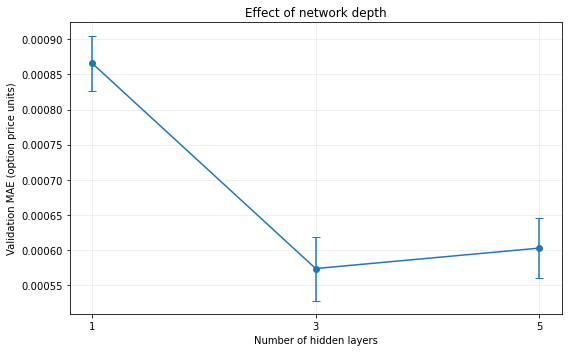

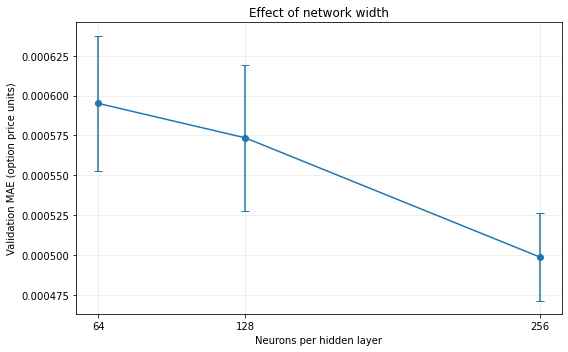

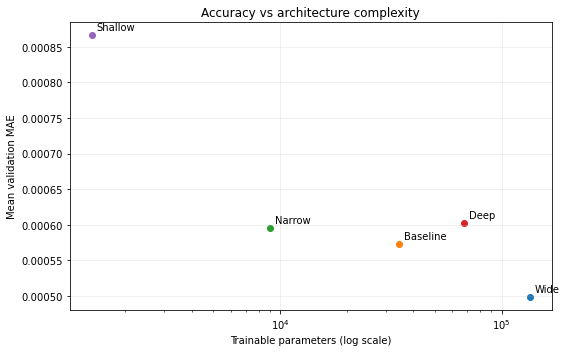

In [20]:
for variable, fixed_column, fixed_value, label, filename in [
    ('layers', 'neurons', 128, 
     'Number of hidden layers', 'depth_vs_mae.png'
    ), 
    ('neurons', 'layers', 3, 
     'Neurons per hidden layer', 'width_vs_mae.png'
    ),
]:
    plot_data = summary[summary[fixed_column] == fixed_value].sort_values(variable)
    fig, ax = plt.subplots(figsize=(8,5))
    x = plot_data[variable].to_numpy()
    y = plot_data['validation_mae_mean'].to_numpy()
    yerr = plot_data['validation_mae_std'].to_numpy() if len(MODEL_SEED) > 1 else None
    ax.errorbar(
        x, y, 
        yerr=yerr, 
        marker='o', 
        capsize=4
    )
    ax.set_xticks(x)
    ax.set_xlabel(label)
    ax.set_ylabel('Validation MAE (option price units)')
    ax.set_title('Effect of network ' + ('depth' if variable == 'layers' else 'width'))
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR/filename, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)
fig, ax = plt.subplots(figsize=(8,5))
for row in summary.itertuples(index=False):
    ax.scatter(row.parameter_count, row.validation_mae_mean)
    ax.annotate(row.architecture, (row.parameter_count, row.validation_mae_mean), 
                xytext=(5,5), textcoords='offset points')
ax.set_xscale('log')
ax.set_xlabel('Trainable parameters (log scale)')
ax.set_ylabel('Mean validation MAE')
ax.set_title('Accuracy vs architecture complexity')
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR/'parameter_vs_mae.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(fig)

In [21]:
xte, _ = tensor_data(test)
actual = test['price'].to_numpy(dtype=float)
final_rows = []

for name in dict.fromkeys([winner, 'Baseline']): 
    for model_seed in MODEL_SEED: 
        checkpoint = trained[(name, model_seed)]
        net = restore_model(checkpoint, name, model_seed)
        with torch.inference_mode():
            prediction = y_scaler.inverse_transform(net(xte).cpu().numpy()).ravel()
        final_rows.append({'architecture': name, 'model_seed': model_seed,
                           **metrics(actual, prediction)})
        predictions = test.copy()
        predictions['predicted_price']=prediction 
        predictions['absolute_error']=np.abs(prediction-actual)
        predictions.to_csv(PREDICTION_DIR/f'test_prediction_{name}_seed_{model_seed}.csv', index=False)
final_trials = pd.DataFrame(final_rows)
final_trials.to_csv(OUTPUT_DIR/'test_trials.csv', index=False)
test_metrics = [c for c in final_trials.columns if c not in ('architecture', 'model_seed')]
final_test = final_trials.groupby('architecture', as_index=False).agg(
    repeats = ('model_seed', 'count'), 
    **{f'{m}_mean':(m, 'mean') for m in test_metrics}, 
    **{f'{m}_std': (m, 'std') for m in test_metrics}
)
final_test.to_csv(OUTPUT_DIR/'final_test_results.csv', index=False)
print(final_test[['architecture', 'repeats', 'mae_mean', 'mae_std', 'rmse_mean', 
                  'p90_absolute_error_mean', 'max_absolute_error_mean']].to_string(index=False))
print(f'\nFiles saved to {OUTPUT_DIR.resolve()}')

architecture  repeats  mae_mean  mae_std  rmse_mean  p90_absolute_error_mean  max_absolute_error_mean
    Baseline        3  0.000615 0.000018   0.000801                 0.001265                 0.003794
        Wide        3  0.000547 0.000028   0.000720                 0.001157                 0.003176

Files saved to /Users/john.madhu_/Desktop/MscThesis/src/heston/experiment_architecture_results/n12000
